In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


Circuit A:


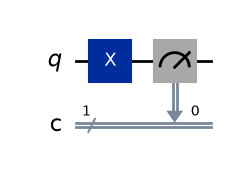

Circuit B:


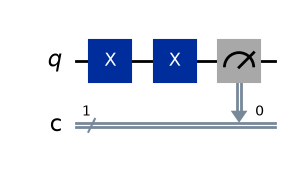

Circuit C:


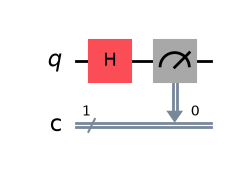

In [3]:
# Circuit A: One X gate
circuit_A = QuantumCircuit(1, 1)
circuit_A.x(0)
circuit_A.measure(0, 0)

# Circuit B: Two X gates
circuit_B = QuantumCircuit(1, 1)
circuit_B.x(0)
circuit_B.x(0)
circuit_B.measure(0, 0)

# Circuit C: One H gate
circuit_C = QuantumCircuit(1, 1)
circuit_C.h(0)
circuit_C.measure(0, 0)

print("Circuit A:")
display(circuit_A.draw("mpl"))

print("Circuit B:")
display(circuit_B.draw("mpl"))

print("Circuit C:")
display(circuit_C.draw("mpl"))

In [4]:
predictions = {
    "Circuit A (X)": {
        "expected": "1",
        "reason": "One X gate flips |0> to |1>."
    },
    "Circuit B (X + X)": {
        "expected": "0",
        "reason": "Two X gates cancel each other."
    },
    "Circuit C (H)": {
        "expected": "0 and 1",
        "reason": "The H gate creates an equal superposition."
    }
}

for circuit_name, details in predictions.items():
    print(circuit_name)
    print("Predicted outcome:", details["expected"])
    print("Reason:", details["reason"])
    print("-" * 40)

Circuit A (X)
Predicted outcome: 1
Reason: One X gate flips |0> to |1>.
----------------------------------------
Circuit B (X + X)
Predicted outcome: 0
Reason: Two X gates cancel each other.
----------------------------------------
Circuit C (H)
Predicted outcome: 0 and 1
Reason: The H gate creates an equal superposition.
----------------------------------------


In [5]:
# Create the simulator
simulator = AerSimulator()

# Store the circuits
circuits = {
    "Circuit A (X)": circuit_A,
    "Circuit B (X + X)": circuit_B,
    "Circuit C (H)": circuit_C
}

# Execute each circuit for 100 shots
results = {}

for name, circuit in circuits.items():
    compiled_circuit = transpile(circuit, simulator)

    job = simulator.run(compiled_circuit, shots=100)
    result = job.result()

    counts = result.get_counts()
    results[name] = counts

    print(f"\n{name}")
    print("Measurement counts:", counts)
    print("Total shots:", sum(counts.values()))


Circuit A (X)
Measurement counts: {'1': 100}
Total shots: 100

Circuit B (X + X)
Measurement counts: {'0': 100}
Total shots: 100

Circuit C (H)
Measurement counts: {'1': 48, '0': 52}
Total shots: 100


In [6]:
for name, counts in results.items():
    plot_histogram(
        counts,
        title=f"{name} — 100 Shots",
        legend=["Measurement Counts"]
    )
    plt.show()

In [8]:

# Step 8: Compare predictions with actual results
# No pandas required

print("=" * 85)
print("CHALLENGE 1: PREDICTED VS ACTUAL RESULTS")
print("=" * 85)

header = (
    f"{'Circuit':<22}"
    f"{'Prediction':<18}"
    f"{'Measured 0':<14}"
    f"{'Measured 1':<14}"
    f"{'Total Shots':<12}"
)
print(header)
print("-" * 85)

for name, counts in results.items():
    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)
    predicted = predictions[name]["expected"]

    print(
        f"{name:<22}"
        f"{predicted:<18}"
        f"{zeros:<14}"
        f"{ones:<14}"
        f"{zeros + ones:<12}"
    )

print("=" * 85)

CHALLENGE 1: PREDICTED VS ACTUAL RESULTS
Circuit               Prediction        Measured 0    Measured 1    Total Shots 
-------------------------------------------------------------------------------------
Circuit A (X)         1                 0             100           100         
Circuit B (X + X)     0                 100           0             100         
Circuit C (H)         0 and 1           52            48            100         


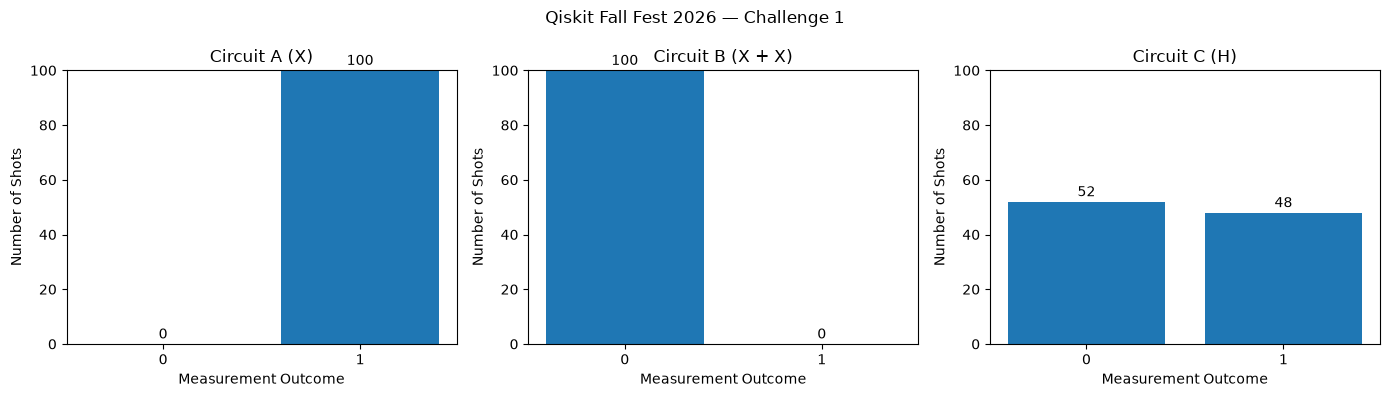

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, counts) in zip(axes, results.items()):
    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    ax.bar(["0", "1"], [zeros, ones])
    ax.set_title(name)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Number of Shots")
    ax.set_ylim(0, 100)

    for x, value in enumerate([zeros, ones]):
        ax.text(x, value + 2, str(value), ha="center")

plt.suptitle("Qiskit Fall Fest 2026 — Challenge 1")
plt.tight_layout()
plt.show()

In [10]:
print("QISKIT FALL FEST 2026")
print("Challenge 1: Predict the Output")
print("=" * 50)

for name, counts in results.items():
    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    print(f"\n{name}")
    print(f"Prediction: {predictions[name]['expected']}")
    print(f"Actual measurement counts: {counts}")

    if name == "Circuit A (X)":
        matched = ones == 100
    elif name == "Circuit B (X + X)":
        matched = zeros == 100
    else:
        matched = zeros > 0 and ones > 0

    print("Prediction matched:", matched)

print("\nConclusion:")
print("Circuit A flips the initial state from 0 to 1.")
print("Circuit B returns the qubit to state 0.")
print("Circuit C produces probabilistic measurement outcomes.")

QISKIT FALL FEST 2026
Challenge 1: Predict the Output

Circuit A (X)
Prediction: 1
Actual measurement counts: {'1': 100}
Prediction matched: True

Circuit B (X + X)
Prediction: 0
Actual measurement counts: {'0': 100}
Prediction matched: True

Circuit C (H)
Prediction: 0 and 1
Actual measurement counts: {'1': 48, '0': 52}
Prediction matched: True

Conclusion:
Circuit A flips the initial state from 0 to 1.
Circuit B returns the qubit to state 0.
Circuit C produces probabilistic measurement outcomes.


## Conclusion

In this experiment, three single-qubit quantum circuits were constructed and simulated using Qiskit, with 100 shots for each circuit.

* **Circuit A:** Applying one X gate to the initial state |0⟩ flips the qubit to |1⟩. The expected measurement outcome is 1.
* **Circuit B:** Applying two consecutive X gates returns the qubit to |0⟩. The expected measurement outcome is 0.
* **Circuit C:** Applying an H gate creates a superposition of |0⟩ and |1⟩. The two measurement outcomes have equal theoretical probabilities of 50%.

The measured results were compared with the theoretical predictions using histograms. Circuits A and B are expected to produce deterministic outcomes in an ideal simulator, while Circuit C produces probabilistic outcomes. Small differences from a 50–50 split in Circuit C are expected because of the finite number of shots.

This experiment demonstrates how quantum gates affect qubit states and how measurement results can be used to verify theoretical predictions.
